In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/ta-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]
# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2024-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]

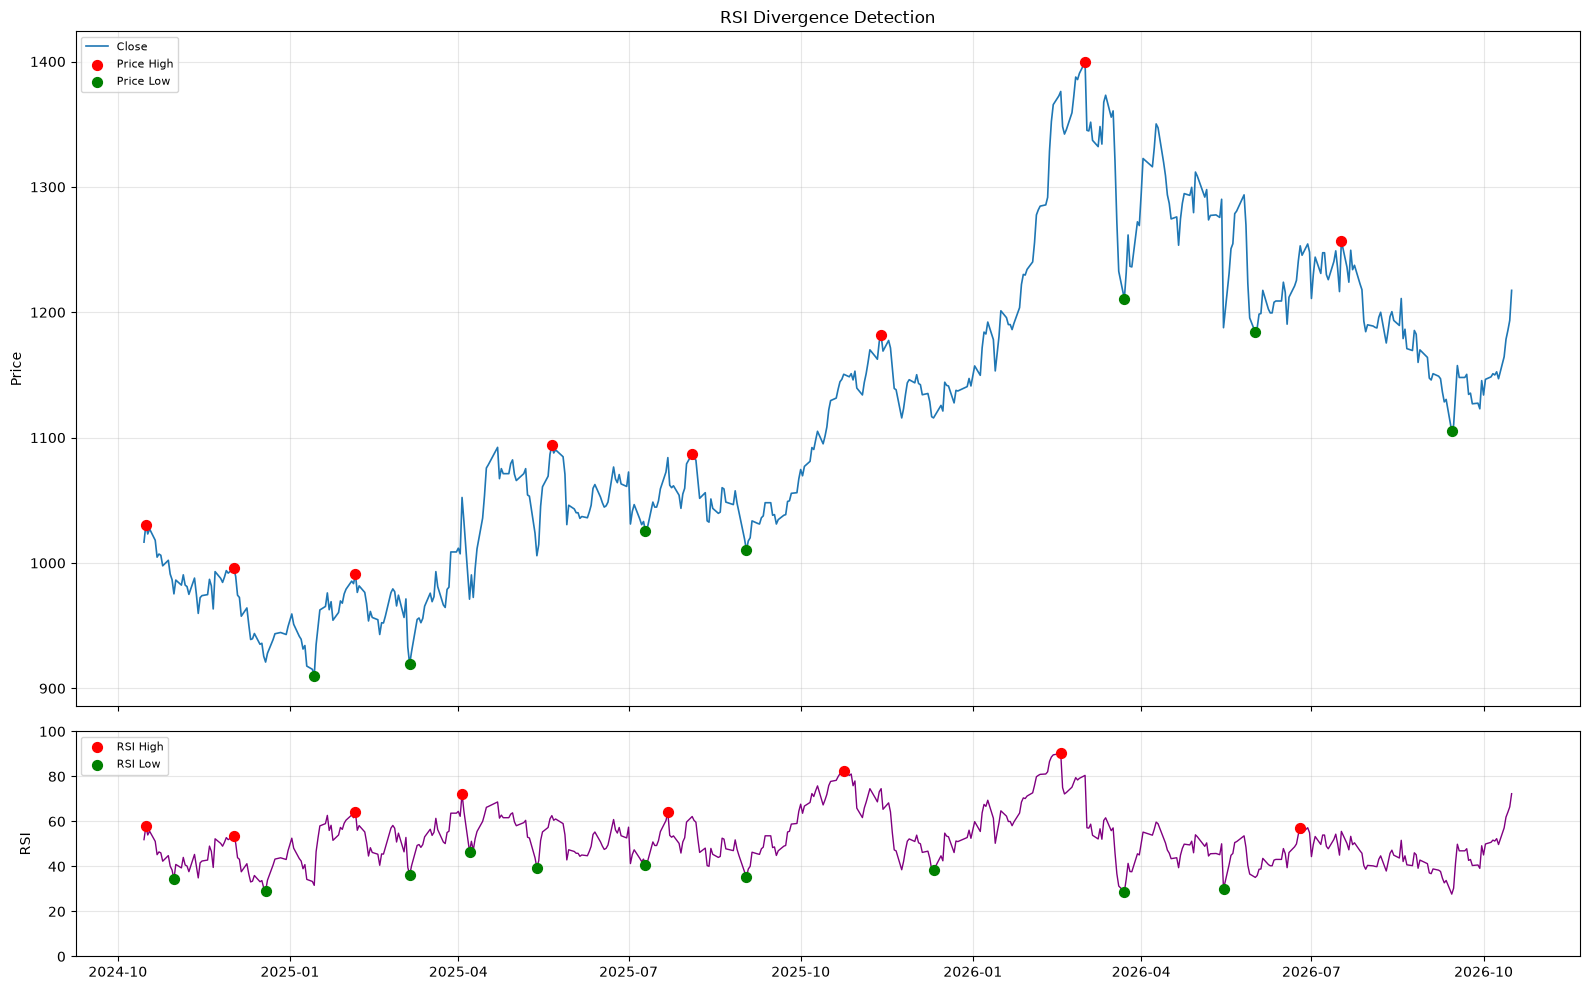

=== Divergence Analysis ===
  No clear divergences detected in recent history.


In [3]:
# === 3. RSI Divergence Detection ===
from scipy.signal import argrelextrema

# Find local extrema
order = 20
high_idx = argrelextrema(df['Close'].values, np.greater, order=order)[0]
low_idx = argrelextrema(df['Close'].values, np.less, order=order)[0]
rsi_high_idx = argrelextrema(df['ta_rsi14'].values, np.greater, order=order)[0]
rsi_low_idx = argrelextrema(df['ta_rsi14'].values, np.less, order=order)[0]

fig, ax = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                       gridspec_kw={'height_ratios': [3, 1]})

# Price
ax[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
for i in high_idx[:10]:
    ax[0].scatter(df.index[i], df['Close'].iloc[i], color='red', s=50, zorder=5, label='Price High' if i == high_idx[0] else "")
for i in low_idx[:10]:
    ax[0].scatter(df.index[i], df['Close'].iloc[i], color='green', s=50, zorder=5, label='Price Low' if i == low_idx[0] else "")
ax[0].set_ylabel('Price')
ax[0].set_title('RSI Divergence Detection')
ax[0].legend(loc='upper left', fontsize=8)
ax[0].grid(True, alpha=0.3)

# RSI
ax[1].plot(df.index, df['ta_rsi14'], color='purple', linewidth=1)
for i in rsi_high_idx[:10]:
    ax[1].scatter(df.index[i], df['ta_rsi14'].iloc[i], color='red', s=50, zorder=5, label='RSI High' if i == rsi_high_idx[0] else "")
for i in rsi_low_idx[:10]:
    ax[1].scatter(df.index[i], df['ta_rsi14'].iloc[i], color='green', s=50, zorder=5, label='RSI Low' if i == rsi_low_idx[0] else "")
ax[1].set_ylabel('RSI')
ax[1].set_ylim(0, 100)
ax[1].grid(True, alpha=0.3)
ax[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

# Detect divergences
print("=== Divergence Analysis ===")
divergences = []
for hi in high_idx[1:]:
    for prev_hi in high_idx[:hi]:
        if df['Close'].iloc[hi] > df['Close'].iloc[prev_hi]:
            # Check if RSI made lower high
            for rhi in rsi_high_idx:
                if prev_hi < rhi < hi:
                    rhi_prev = None
                    for rhp in rsi_high_idx:
                        if rhp < prev_hi:
                            rhi_prev = rhp
                    if rhi_prev and df['ta_rsi14'].iloc[rhi] < df['ta_rsi14'].iloc[rhi_prev]:
                        divergences.append(('Bearish', df.index[prev_hi], df.index[hi]))
                        break
            break

for li in low_idx[1:]:
    for prev_li in low_idx[:li]:
        if df['Close'].iloc[li] < df['Close'].iloc[prev_li]:
            for rli in rsi_low_idx:
                if prev_li < rli < li:
                    rli_prev = None
                    for rlp in rsi_low_idx:
                        if rlp < prev_li:
                            rli_prev = rlp
                    if rli_prev and df['ta_rsi14'].iloc[rli] > df['ta_rsi14'].iloc[rli_prev]:
                        divergences.append(('Bullish', df.index[prev_li], df.index[li]))
                        break
            break

if divergences:
    for div_type, start, end in divergences[-5:]:
        print(f"  {div_type} Divergence: {start.date()} → {end.date()}")
else:
    print("  No clear divergences detected in recent history.")

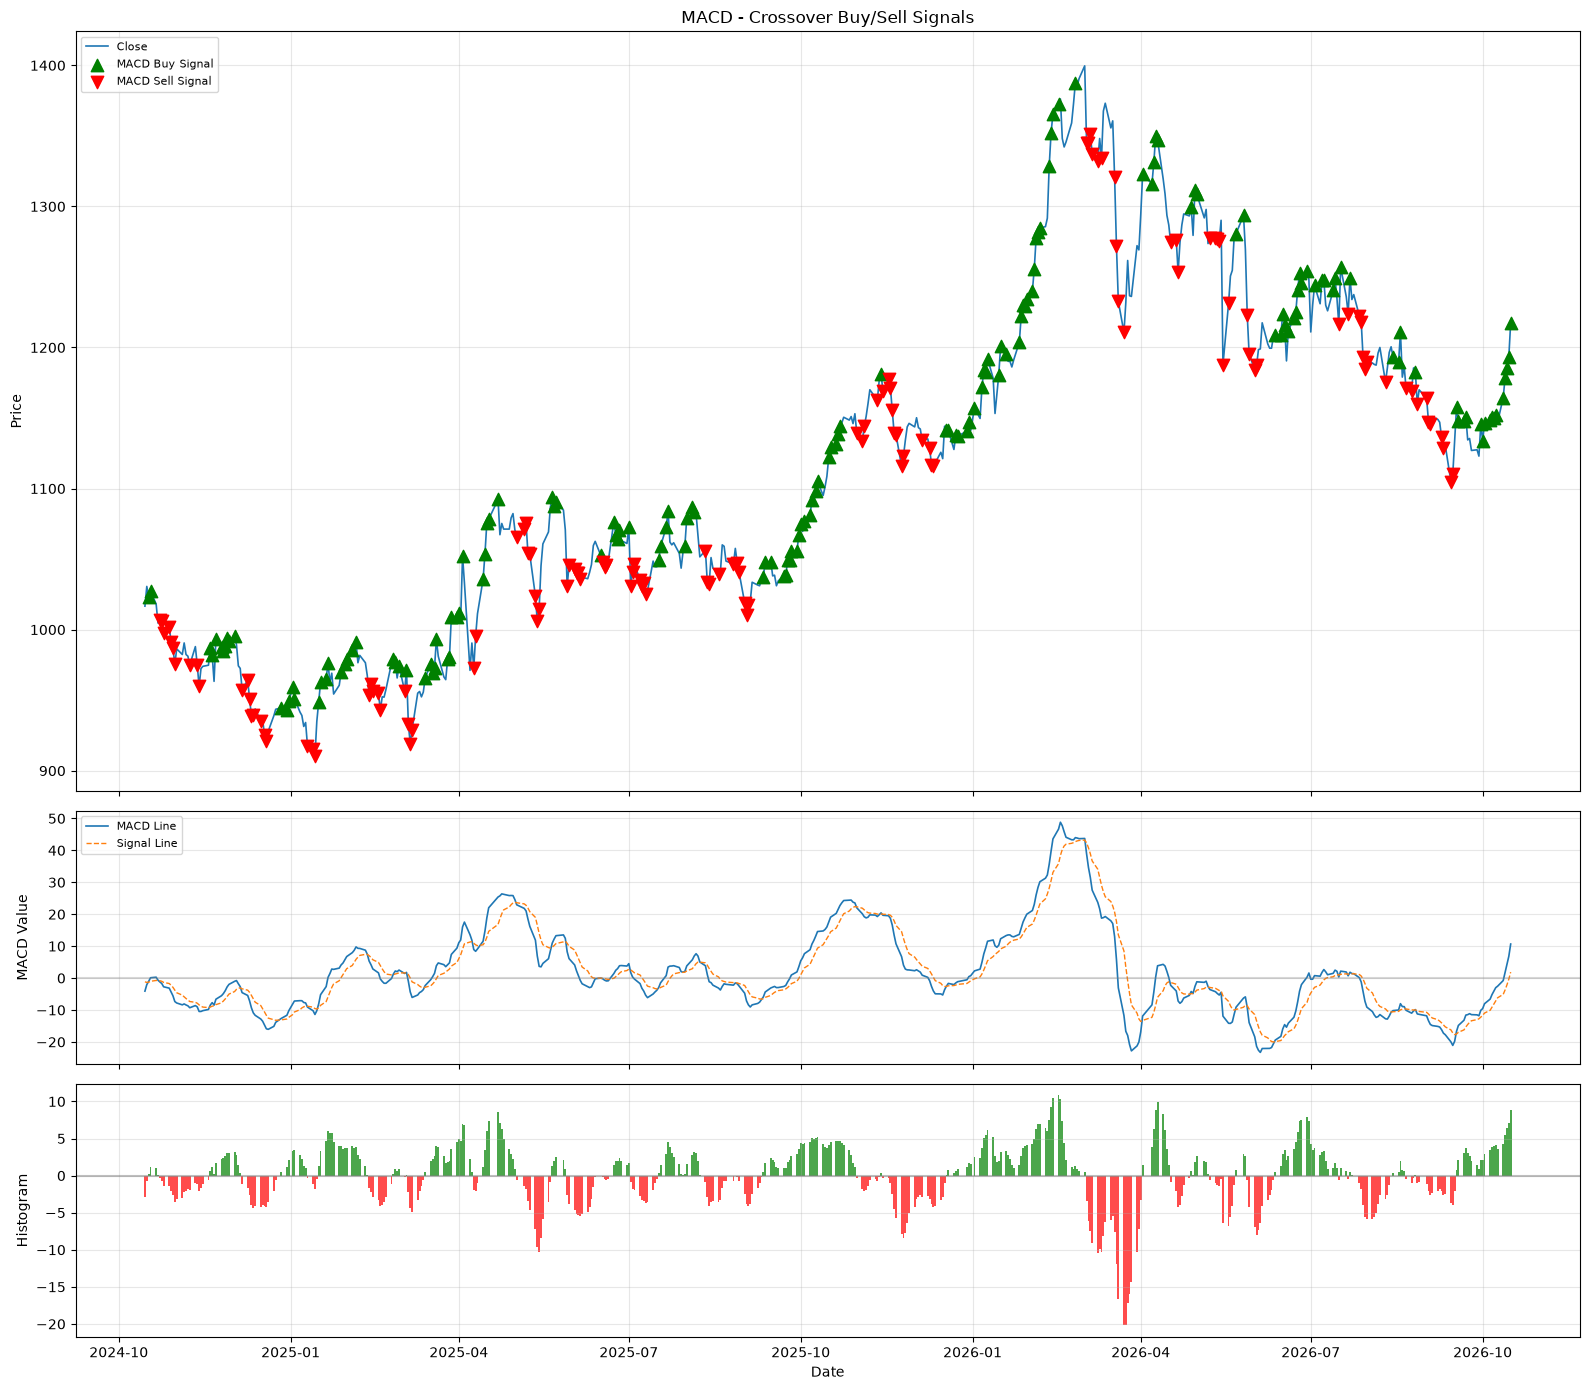

=== MACD Statistics ===
Current MACD Line: 10.6639
Current Signal: 1.8635
Current Histogram: 8.8003
MACD > Signal (Bullish): 53.7%
MACD > 0: 48.2%
Total Buy Signals (crossover): 161
Total Sell Signals (crossover): 123


In [4]:
# === 4. MACD Analysis ===
fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1, 1]})

# Price + MACD signal markers
axes[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
# Buy signals: MACD crosses above Signal
buy_mask = (df['ta_macd_line'] > df['ta_macd_signal']) & (df['ta_macd_line'].diff() > df['ta_macd_signal'].diff())
sell_mask = (df['ta_macd_line'] < df['ta_macd_signal']) & (df['ta_macd_line'].diff() < df['ta_macd_signal'].diff())

axes[0].scatter(df.index[buy_mask], df['Close'][buy_mask], marker='^', color='green',
                s=80, zorder=5, label='MACD Buy Signal')
axes[0].scatter(df.index[sell_mask], df['Close'][sell_mask], marker='v', color='red',
                s=80, zorder=5, label='MACD Sell Signal')
axes[0].set_ylabel('Price')
axes[0].set_title('MACD - Crossover Buy/Sell Signals')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# MACD Line, Signal Line
axes[1].plot(df.index, df['ta_macd_line'], label='MACD Line', linewidth=1.2)
axes[1].plot(df.index, df['ta_macd_signal'], label='Signal Line', linewidth=1, linestyle='--')
axes[1].axhline(y=0, color='gray', linestyle='-', alpha=0.3)
axes[1].set_ylabel('MACD Value')
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

# Histogram
colors = ['green' if v >= 0 else 'red' for v in df['ta_macd_histogram']]
axes[2].bar(df.index, df['ta_macd_histogram'], color=colors, alpha=0.7, width=1)
axes[2].axhline(y=0, color='gray', linestyle='-', alpha=0.5)
axes[2].set_ylabel('Histogram')
axes[2].set_xlabel('Date')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics
print("=== MACD Statistics ===")
print(f"Current MACD Line: {df['ta_macd_line'].iloc[-1]:.4f}")
print(f"Current Signal: {df['ta_macd_signal'].iloc[-1]:.4f}")
print(f"Current Histogram: {df['ta_macd_histogram'].iloc[-1]:.4f}")
print(f"MACD > Signal (Bullish): {(df['ta_macd_line'] > df['ta_macd_signal']).mean()*100:.1f}%")
print(f"MACD > 0: {(df['ta_macd_line'] > 0).mean()*100:.1f}%")
print(f"Total Buy Signals (crossover): {buy_mask.sum()}")
print(f"Total Sell Signals (crossover): {sell_mask.sum()}")

/tmp/ipykernel_11838/3570213080.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_roc.legend(loc='upper left', fontsize=9)


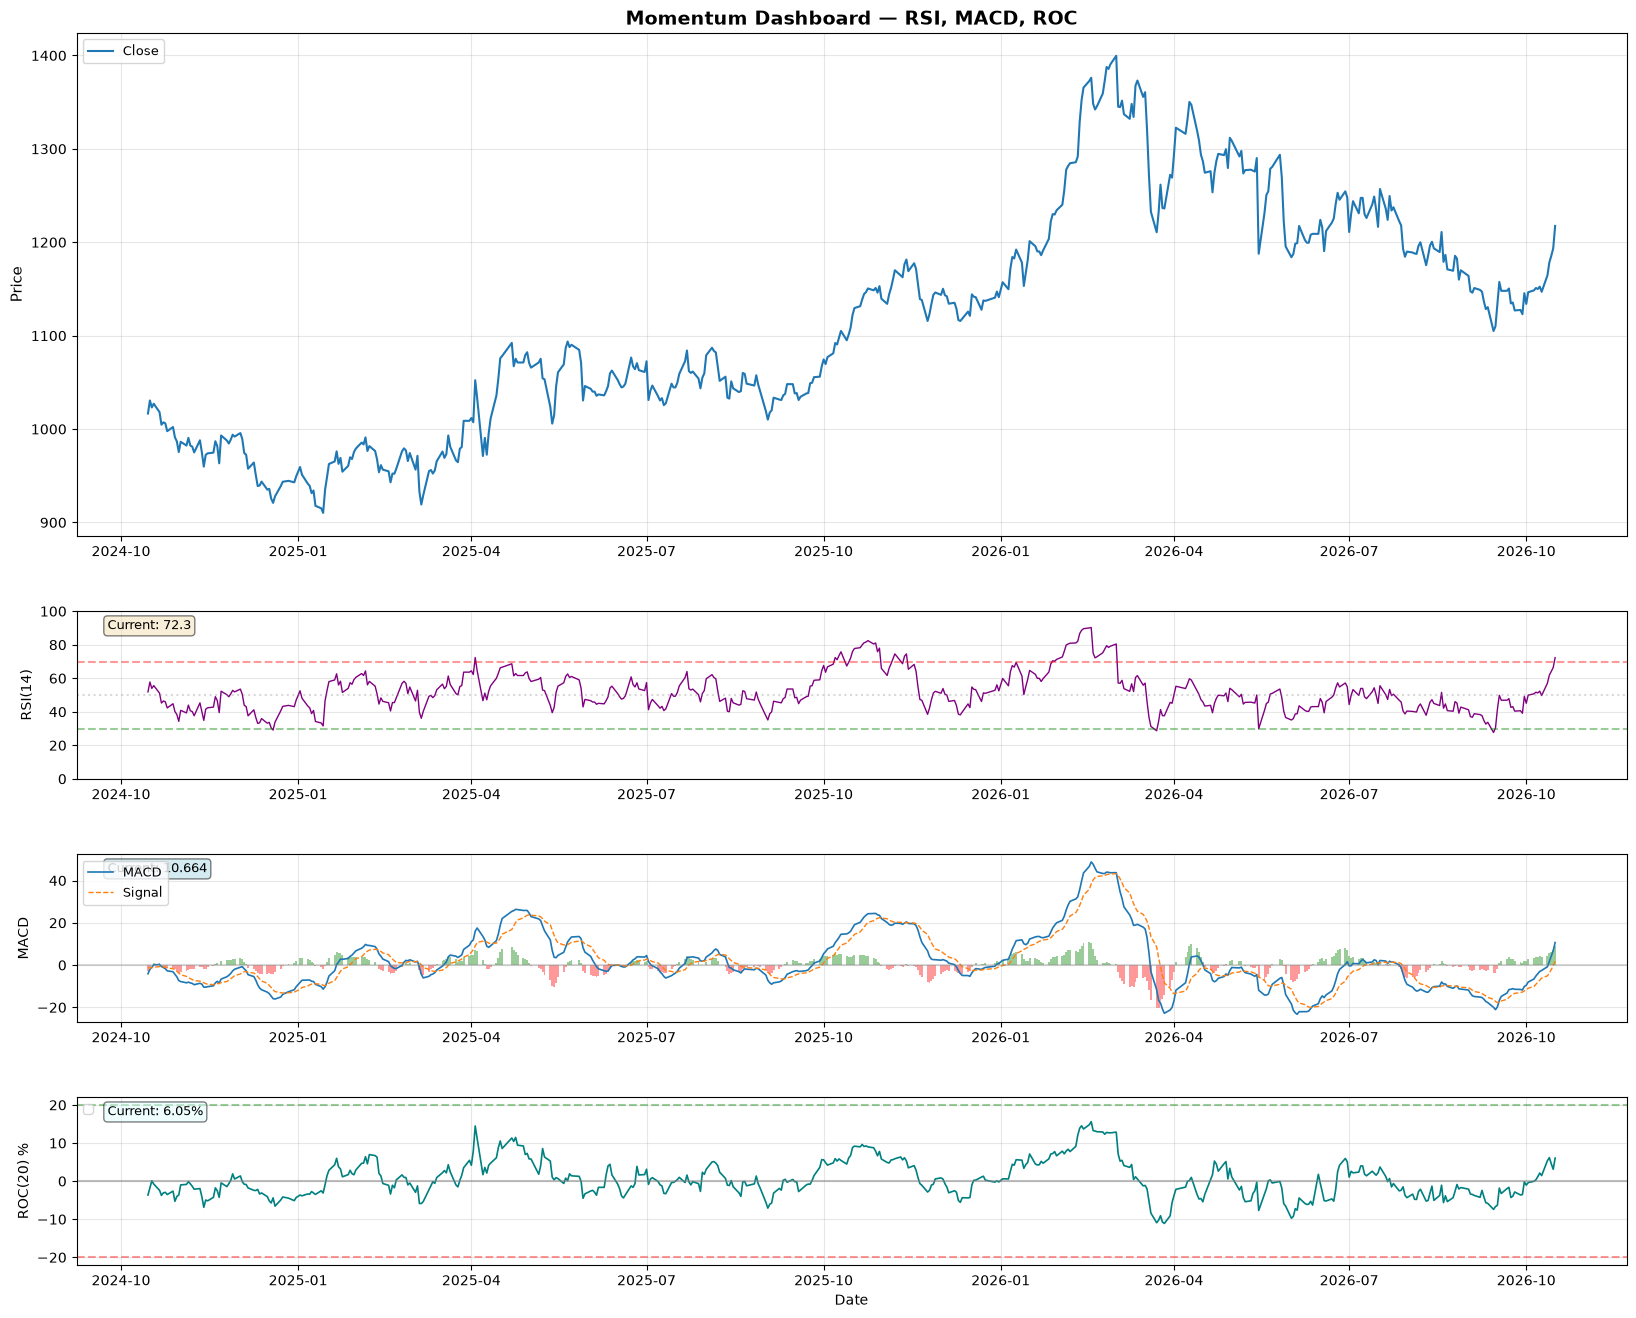

In [6]:
# === 7. Full Momentum Dashboard ===
fig = plt.figure(figsize=(20, 16))
gs = fig.add_gridspec(4, 1, height_ratios=[3, 1, 1, 1], hspace=0.3)

ax_price = fig.add_subplot(gs[0])
ax_rsi = fig.add_subplot(gs[1], sharex=ax_price)
ax_macd = fig.add_subplot(gs[2], sharex=ax_price)
ax_roc = fig.add_subplot(gs[3], sharex=ax_price)

# Price
ax_price.plot(df.index, df['Close'], label='Close', linewidth=1.5)
ax_price.set_ylabel('Price', fontsize=11)
ax_price.set_title('Momentum Dashboard — RSI, MACD, ROC', fontsize=14, fontweight='bold')
ax_price.legend(loc='upper left', fontsize=9)
ax_price.grid(True, alpha=0.3)

# RSI
colors_rsi = ['red' if v > 70 else ('green' if v < 30 else 'purple') for v in df['ta_rsi14']]
ax_rsi.plot(df.index, df['ta_rsi14'], color='purple', linewidth=1)
ax_rsi.axhline(y=70, color='r', linestyle='--', alpha=0.4)
ax_rsi.axhline(y=30, color='g', linestyle='--', alpha=0.4)
ax_rsi.axhline(y=50, color='gray', linestyle=':', alpha=0.3)
ax_rsi.set_ylabel('RSI(14)', fontsize=10)
ax_rsi.set_ylim(0, 100)
ax_rsi.grid(True, alpha=0.3)
ax_rsi.text(0.02, 0.95, f'Current: {df["ta_rsi14"].iloc[-1]:.1f}',
            transform=ax_rsi.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# MACD
ax_macd.plot(df.index, df['ta_macd_line'], label='MACD', linewidth=1.2)
ax_macd.plot(df.index, df['ta_macd_signal'], label='Signal', linewidth=1, linestyle='--')
hist_colors = ['green' if v >= 0 else 'red' for v in df['ta_macd_histogram']]
ax_macd.bar(df.index, df['ta_macd_histogram'], color=hist_colors, alpha=0.4, width=1)
ax_macd.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
ax_macd.set_ylabel('MACD', fontsize=10)
ax_macd.legend(loc='upper left', fontsize=9)
ax_macd.grid(True, alpha=0.3)
ax_macd.text(0.02, 0.95, f'Current: {df["ta_macd_line"].iloc[-1]:.3f}',
            transform=ax_macd.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

# ROC
ax_roc.plot(df.index, df['ta_roc20'], color='teal', linewidth=1.2)
ax_roc.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax_roc.axhline(y=20, color='g', linestyle='--', alpha=0.4)
ax_roc.axhline(y=-20, color='r', linestyle='--', alpha=0.4)
ax_roc.set_ylabel('ROC(20) %', fontsize=10)
ax_roc.set_xlabel('Date', fontsize=10)
ax_roc.legend(loc='upper left', fontsize=9)
ax_roc.grid(True, alpha=0.3)
ax_roc.text(0.02, 0.95, f'Current: {df["ta_roc20"].iloc[-1]:.2f}%',
            transform=ax_roc.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.5))

plt.show()


=== EMA50 Signals (Last 10 Years) ===
Time above EMA50: 52.8%
EMA20 > EMA50:    57.9%


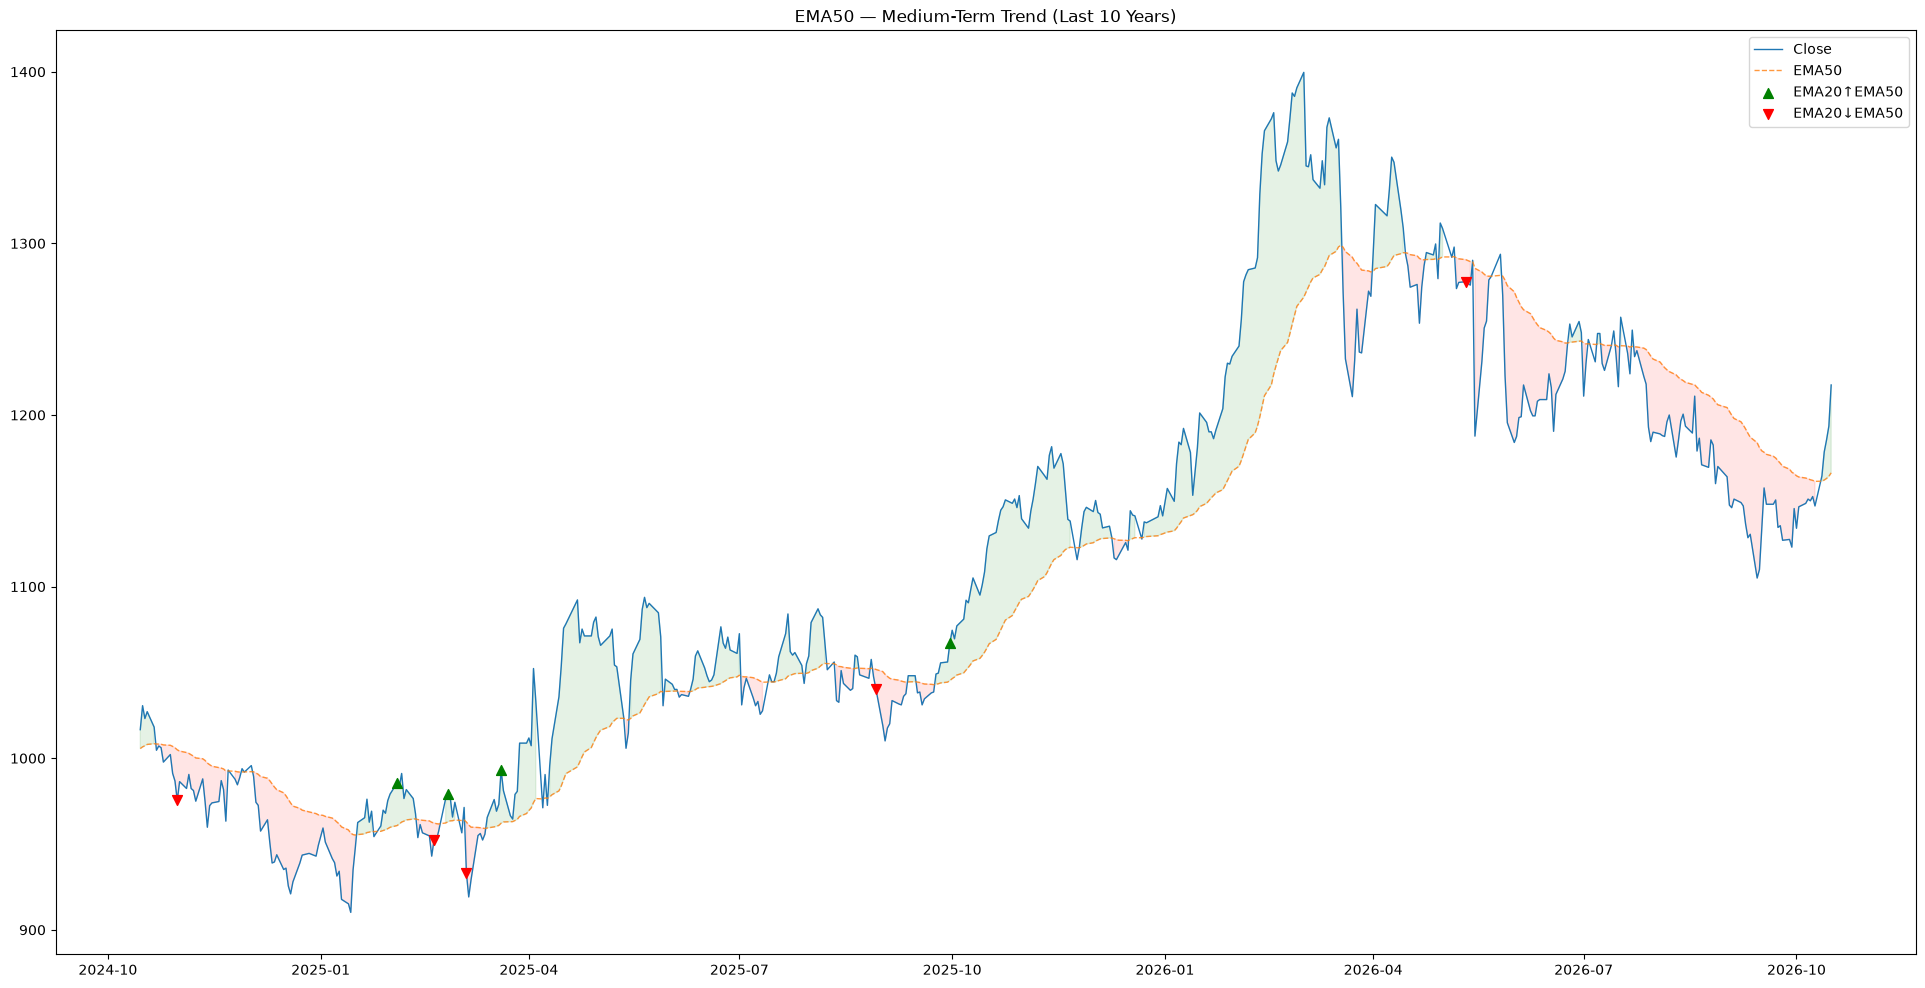

In [8]:
# === 3. EMA50 ===
ema50 = df["ta_ema50"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=3)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]
ema50 = df_recent["ta_ema50"]

df_recent["price_above_ema50"] = close > ema50
df_recent["ema20_above_ema50"] = ema20 > ema50
df_recent["prev_ema20_above_ema50"] = df_recent["ema20_above_ema50"].shift(1)
df_recent["ema50_buy_signal"] = df_recent["ema20_above_ema50"] == True
df_recent["ema50_sell_signal"] = df_recent["ema20_above_ema50"] == False
df_recent["golden_cross"] = (df_recent["ema20_above_ema50"] == True) & (df_recent["prev_ema20_above_ema50"] == False)
df_recent["death_cross"] = (df_recent["ema20_above_ema50"] == False) & (df_recent["prev_ema20_above_ema50"] == True)

print("\n=== EMA50 Signals (Last 10 Years) ===")
print(f"Time above EMA50: {(df_recent['price_above_ema50']).mean()*100:.1f}%")
print(f"EMA20 > EMA50:    {(df_recent['ema20_above_ema50']).mean()*100:.1f}%")

ema50_cross_buy_idx = df_recent[df_recent["golden_cross"]].index
ema50_cross_buy_prices = close[ema50_cross_buy_idx]
ema50_cross_sell_idx = df_recent[df_recent["death_cross"]].index
ema50_cross_sell_prices = close[ema50_cross_sell_idx]

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema50, label="EMA50", linestyle="--", linewidth=1, alpha=0.8)
ax.fill_between(close.index, close, ema50, where=(close >= ema50), alpha=0.1, color="green")
ax.fill_between(close.index, close, ema50, where=(close < ema50), alpha=0.1, color="red")
ax.scatter(ema50_cross_buy_idx, ema50_cross_buy_prices, marker="^", color="green", s=50, label="EMA20↑EMA50", zorder=5)
ax.scatter(ema50_cross_sell_idx, ema50_cross_sell_prices, marker="v", color="red", s=50, label="EMA20↓EMA50", zorder=5)
ax.legend()
ax.set_title("EMA50 — Medium-Term Trend (Last 10 Years)")
plt.show()

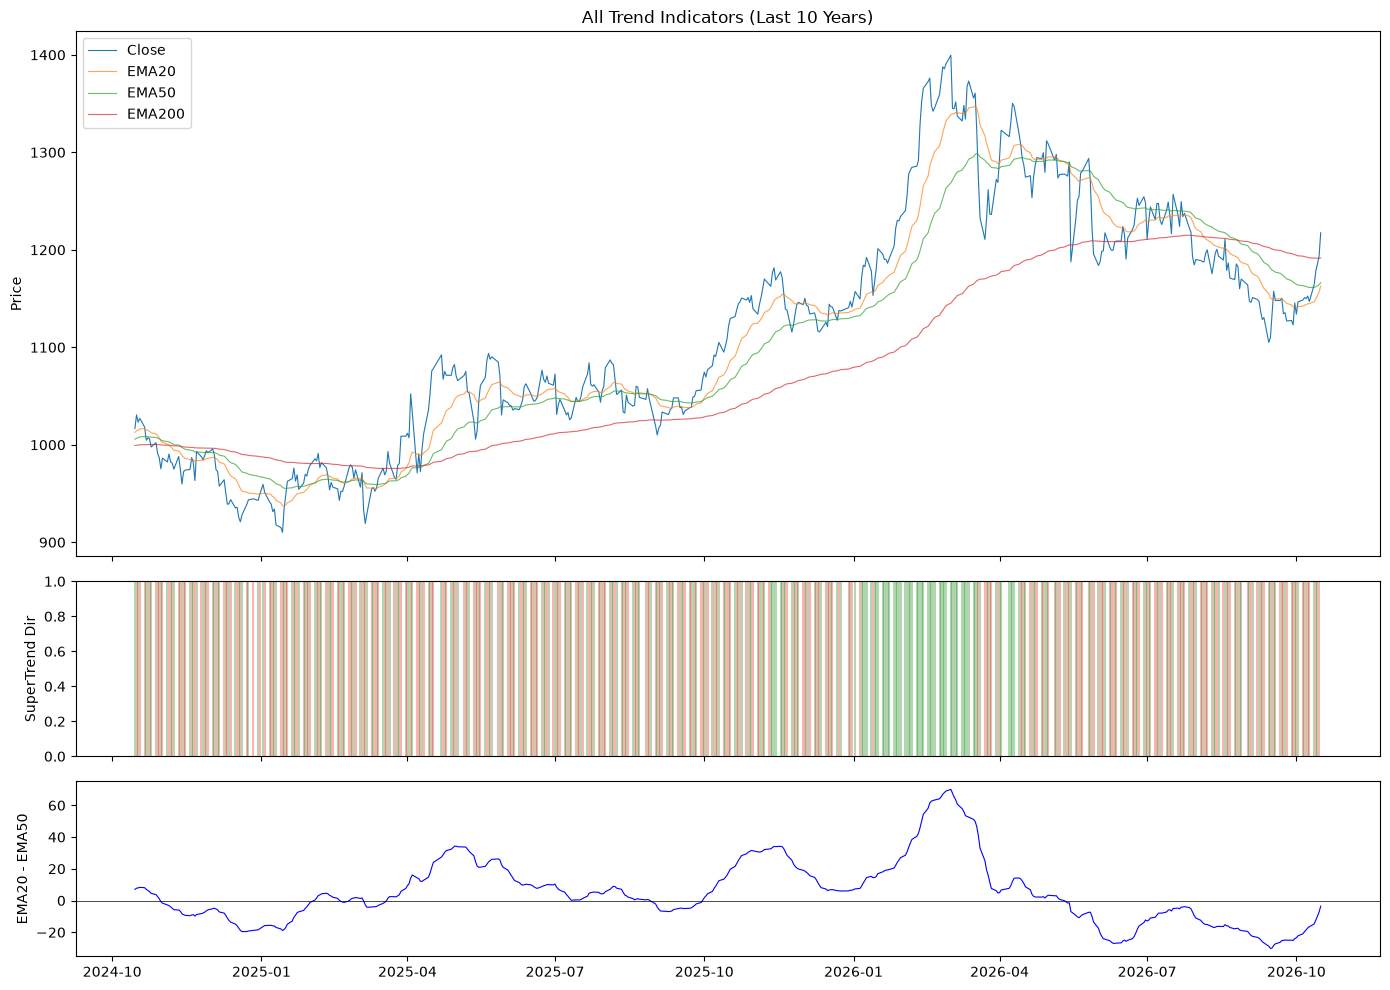

In [11]:
# === 8. Combined Timeline ===
# --- FILTER TO LAST 10 YEARS (self-contained) ---
cutoff8 = df.index.max() - pd.DateOffset(years=3)
df8 = df[df.index >= cutoff8]
close8 = df8["Close"]
ema20_8 = df8["ta_ema20"]
ema50_8 = df8["ta_ema50"]
ema200_8 = df8["ta_ema200"]
st_dir_8 = df8["ta_supertrend_direction"].fillna(-1)

df8["score_ema20"] = (close8 > ema20_8).astype(int) * 2 - 1
df8["score_ema50"] = (close8 > ema50_8).astype(int) * 2 - 1
df8["score_ema200"] = (close8 > ema200_8).astype(int) * 2 - 1
df8["score_cross"] = (ema50_8 > ema200_8).astype(int) * 2 - 1

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})

axes[0].plot(close8.index, close8, label="Close", linewidth=0.8)
axes[0].plot(close8.index, ema20_8, label="EMA20", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema50_8, label="EMA50", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema200_8, label="EMA200", linewidth=0.8, alpha=0.7)
axes[0].set_ylabel("Price")
axes[0].legend(loc="upper left")
axes[0].set_title("All Trend Indicators (Last 10 Years)")

st_colors = st_dir_8.map({1: "green", -1: "red"})
for i in range(len(df8) - 1):
    axes[1].axvline(df8.index[i], color=st_colors.iloc[i], alpha=0.3)
axes[1].set_ylabel("SuperTrend Dir")

df8["ema_diff"] = ema20_8 - ema50_8
axes[2].plot(df8.index, df8["ema_diff"], color="blue", linewidth=0.8)
axes[2].axhline(0, color="black", linestyle="-", linewidth=0.5)
axes[2].set_ylabel("EMA20 - EMA50")

plt.tight_layout()
plt.show()

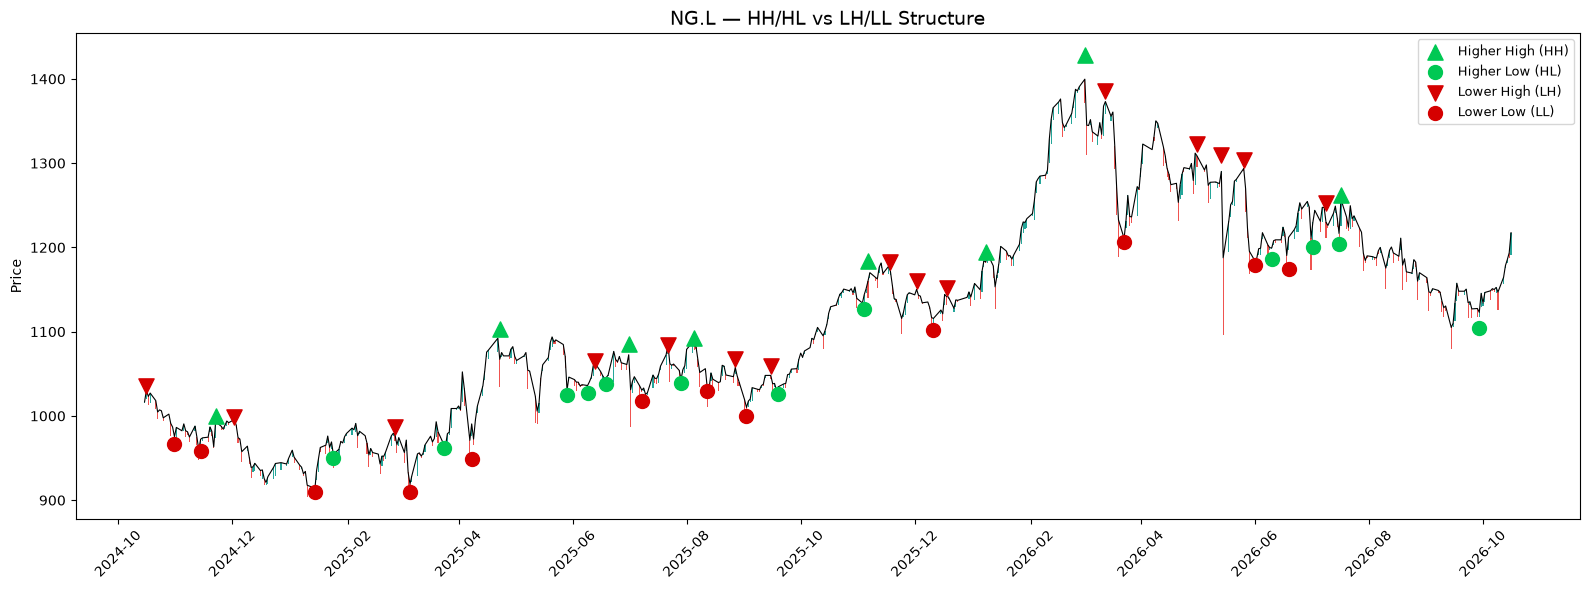

In [16]:
# ============================================================
# Higher High / Higher Low (Bullish) & Lower High / Lower Low (Bearish)
# ============================================================
# ============================================================
# chart helpers
# ============================================================
def make_ax(figsize=(16, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.xticks(rotation=45)
    return fig, ax

fig, ax = make_ax()

# candlestick
d_up = df["Close"] >= df["Open"]
d_down = ~d_up
ax.bar(df.index[d_up], df["Close"][d_up] - df["Open"][d_up], 0.6,
       bottom=df["Open"][d_up], color="#26a69a")
ax.bar(df.index[d_down], df["Close"][d_down] - df["Open"][d_down], 0.6,
       bottom=df["Close"][d_down], color="#ef5350")
ax.plot(df["Close"], color="black", linewidth=0.8)

# HH — green triangles
hh = df["ta_hh"] == 1
if hh.any():
    ax.scatter(df.index[hh], df["High"][hh], color="#00c853",
               marker="^", s=120, zorder=5, label="Higher High (HH)")

# HL — green circles
hl = df["ta_hl"] == 1
if hl.any():
    ax.scatter(df.index[hl], df["Low"][hl], color="#00c853",
               marker="o", s=100, zorder=5, label="Higher Low (HL)")

# LH — red triangles
lh = df["ta_lh"] == 1
if lh.any():
    ax.scatter(df.index[lh], df["High"][lh], color="#d50000",
               marker="v", s=120, zorder=5, label="Lower High (LH)")

# LL — red circles
ll = df["ta_ll"] == 1
if ll.any():
    ax.scatter(df.index[ll], df["Low"][ll], color="#d50000",
               marker="o", s=100, zorder=5, label="Lower Low (LL)")

ax.set_title(f"{ticker} — HH/HL vs LH/LL Structure", fontsize=14)
ax.legend(fontsize=9)
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()